# 05 · Block 4 — track centre

Goal: on one band, turn the blobs into one track-centre position. The question is which blobs are the boundaries.

In [1]:
%load_ext autoreload
%autoreload 2
import math
import numpy as np
import matplotlib.pyplot as plt
from helpers import SyntheticTrack, synthetic_drive, show, table, use_style
use_style()

from lanedet.camera import Camera
from lanedet.mask import to_float, yellow_mask
from lanedet.scan import band_profile, find_lines

base = SyntheticTrack()
cam = Camera(base.width, base.height, base.focal, base.cam_height, base.v_horizon)
NEAR = (68, 75)
v = sum(NEAR) / 2
half_px = float(cam.width_px(base.half_width, v))

def blobs(frame, band=NEAR):
    return find_lines(band_profile(yellow_mask(to_float(frame)), band))

## The cases

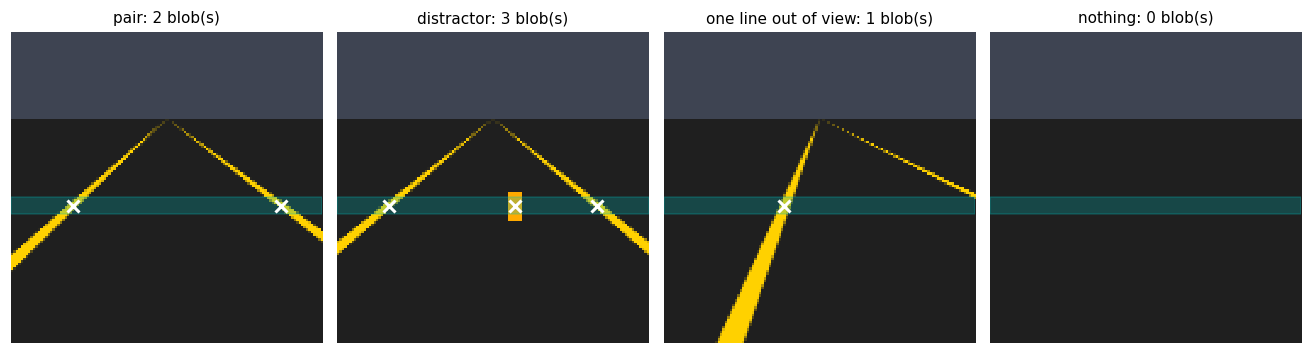

In [2]:
cone = SyntheticTrack().render()
cone[66:78, 70:76] = (255, 170, 0)
cases = {
    "pair": (SyntheticTrack(offset=0.03).render(), 0.03),
    "distractor": (cone, 0.0),
    "one line out of view": (SyntheticTrack(offset=0.2).render(), 0.2),
    "nothing": (SyntheticTrack(draw_left=False, draw_right=False).render(), 0.0),
}
fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
for a, (name, (fr, _)) in zip(ax, cases.items()):
    found = blobs(fr)
    a.imshow(fr, extent=(0, 128, 128, 0))
    a.axhspan(*NEAR, color="c", alpha=0.25)
    for l in found:
        a.plot(l.u, v, "wx", ms=8, mew=2)
    a.set_title(f"{name}: {len(found)} blob(s)")
    a.axis("off")
plt.tight_layout()
plt.show()

## Design

**Pairs first.** The camera block gives the expected spacing on this row, `2 · half_px`. Among all pairs of blobs keep the one whose spacing matches best, within a relative tolerance. A cone between the lines forms pairs with the wrong spacing and is ignored.

**One blob.** It is the left boundary (centre = `u + half_px`) or the right one (centre = `u − half_px`). The image alone cannot decide. Use a prior — where the centre was a moment ago — and keep the closer hypothesis.

**No blobs.** Report nothing. The detector holds its last estimate.

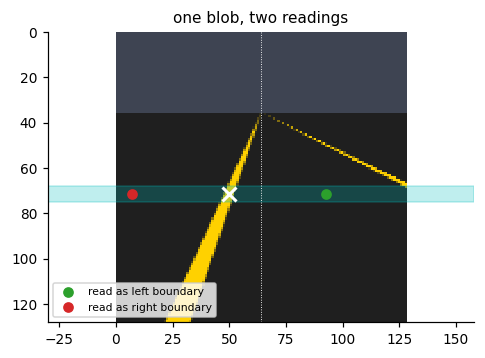

In [3]:
fr, _ = cases["one line out of view"]
(line,) = blobs(fr)

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.imshow(fr, extent=(0, 128, 128, 0))
ax.axhspan(*NEAR, color="c", alpha=0.25)
ax.plot(line.u, v, "wx", ms=9, mew=2)
ax.plot(line.u + half_px, v, "o", color="tab:green", label="read as left boundary")
ax.plot(line.u - half_px, v, "o", color="tab:red", label="read as right boundary")
ax.axvline(64, color="w", lw=0.6, ls=":")
ax.set(xlim=(-30, 158), title="one blob, two readings")
ax.grid(False)
ax.legend(loc="lower left", fontsize=7)
plt.show()

The image centre is a weak prior: it fails once the car is about half a track-width off centre (06 shows the sign flip). The last frame's estimate is a strong one — consecutive frames differ by millimetres. The detector carries it as state.

**Confidence**: pair → `1 − error / tolerance`; one blob → 0.5 (the width is assumed, not seen); ×0.8 if a blob touches the border; none → 0.

This cell saves the block to `lanedet/centre.py`. The next cell imports it.

In [4]:
%%writefile lanedet/centre.py
"""Block 4 - track centre on one band: decide which blobs are the boundaries, return the midpoint."""

from dataclasses import dataclass, field

from .scan import Line


@dataclass
class BandEstimate:
    u: float | None  # track centre column, px (None = nothing to go on)
    case: str  # "pair", "left", "right", "none"
    confidence: float  # 0..1
    used: list = field(default_factory=list)  # the Line(s) the estimate is based on


def estimate_centre(
    lines: list[Line],
    half_px: float,
    prior_u: float,
    tolerance: float = 0.35,
    single_confidence: float = 0.5,
) -> BandEstimate:
    """
    lines      : blobs found on this band
    half_px    : expected track half-width on this band, px (from the camera model)
    prior_u    : where we expect the centre (last frame's estimate, or the image centre)
    tolerance  : accepted relative error between a pair's spacing and the expected width
    """
    best = None
    for i, a in enumerate(lines):
        for b in lines[i + 1 :]:
            err = abs((b.u - a.u) - 2 * half_px) / (2 * half_px)
            if err < tolerance and (best is None or err < best[0]):
                best = (err, a, b)
    if best is not None:
        err, a, b = best
        conf = 1.0 - err / tolerance
        if a.clipped or b.clipped:
            conf *= 0.8
        return BandEstimate((a.u + b.u) / 2, "pair", conf, [a, b])

    candidates = []
    for line in lines:
        candidates.append((abs(line.u + half_px - prior_u), line.u + half_px, "left", line))
        candidates.append((abs(line.u - half_px - prior_u), line.u - half_px, "right", line))
    if candidates:
        _, u, side, line = min(candidates, key=lambda c: c[0])
        conf = single_confidence * (0.8 if line.clipped else 1.0)
        return BandEstimate(u, side, conf, [line])

    return BandEstimate(None, "none", 0.0, [])

Writing lanedet/centre.py


In [5]:
from lanedet.centre import estimate_centre

def true_centre_u(offset):
    return float(cam.to_pixel_u(SyntheticTrack(offset=offset).centre_x(float(cam.distance(v))), v))

rows = []
for name, (fr, off) in cases.items():
    est = estimate_centre(blobs(fr), half_px, prior_u=cam.cx)
    rows.append({"case": name, "result": est.case, "centre u": "–" if est.u is None else est.u,
                 "true u": true_centre_u(off), "confidence": est.confidence})
table(rows)

case,result,centre u,true u,confidence
pair,pair,68.279,68.279,0.999
distractor,pair,64.000,64.000,0.994
one line out of view,left,92.465,92.528,0.500
nothing,none,–,64.000,0.000


## Check

In [6]:
for name in ("pair", "distractor", "one line out of view"):
    fr, off = cases[name]
    est = estimate_centre(blobs(fr), half_px, prior_u=cam.cx)
    assert abs(est.u - true_centre_u(off)) < 0.5, name
assert estimate_centre(blobs(cases["distractor"][0]), half_px, cam.cx).case == "pair"
assert estimate_centre([], half_px, cam.cx).u is None
(line,) = blobs(cases["one line out of view"][0])
assert estimate_centre([line], half_px, prior_u=line.u + half_px).case == "left"
assert estimate_centre([line], half_px, prior_u=line.u - half_px).case == "right"

## Exercises

1. Move the cone onto a boundary. What does the block return, and why?
2. Render a track with `half_width=0.36` while the block assumes 0.30. How low can `tolerance` go before pairs are lost?